# AlexNet 2012 on Tiny ImageNet

Reproducing AlexNet (Krizhevsky et al., 2012), adapting, training and bechmarking it on Tiny ImageNet 64x64.

In [43]:
# Standard library
import os
import shutil
import urllib.request
import zipfile
from pathlib import Path

# Third-party
import lightning as L
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchmetrics.classification import MulticlassAccuracy

from lightning.pytorch.loggers import TensorBoardLogger
from lightning.pytorch.loggers import CSVLogger
import pandas as pd
import matplotlib.pyplot as plt

In [44]:
URL          = "http://cs231n.stanford.edu/tiny-imagenet-200.zip"
DATA_ROOT    = Path("data")
DATA_DIR     = DATA_ROOT / "tiny-imagenet-200"

NUM_CLASSES  = 200
NUM_EPOCHS   = 60
LR           = 0.02      # linearly scaled from paper: LR=0.01 BS=128
BATCH_SIZE   = 256
WEIGHT_DECAY = 5e-4
MOMENTUM     = 0.9
SEED         = 42

L.seed_everything(SEED, workers=True)
torch.backends.cudnn.benchmark = True
torch.set_float32_matmul_precision("high")

Seed set to 42


### Original* AlexNet 2012
*: The original paper effectively split conv layers between 2 GPUs due to hardware constraints at the time. Furthermore, it applied additional data-augmentation techniques to its input data, like PCA. It is also important to note that the original architecture was not made in pytorch but raw cuda. The vanilla architecture presented here is thus very close to the true original, but not exactly.

In [45]:
class OriginalAlexNet(nn.Module):
    
    """
    Vanilla AlexNet 2012 with original conv schedule, designed for 224x224.

    Spatial trajectory:
        224 -> 55 -> 27 -> 27 -> 13 -> 13 -> 13 -> 6   (original paper input)
         64 -> 15 ->  7 ->  7 ->  3 ->  3 ->  3 -> 1   (Tiny ImageNet input)

    At 64x64 the trunk produces a 1x1 map, so AdaptiveAvgPool2d((6,6))
    broadcasts that single vector 36x into the first FC. The 9216-dim
    FC input is therefore nominally faithful to the paper but rank-redundant
    (only 256 values are unique).
    """

    def __init__(self, num_classes: int = NUM_CLASSES):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 96, kernel_size=11, stride=4, padding=2),
            nn.ReLU(inplace=True),
            nn.LocalResponseNorm(size=5, alpha=1e-4, beta=0.75, k=2.0),
            nn.MaxPool2d(kernel_size=3, stride=2),

            nn.Conv2d(96, 256, kernel_size=5, padding=2),
            nn.ReLU(inplace=True),
            nn.LocalResponseNorm(size=5, alpha=1e-4, beta=0.75, k=2.0),
            nn.MaxPool2d(kernel_size=3, stride=2),

            nn.Conv2d(256, 384, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),

            nn.Conv2d(384, 384, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),

            nn.Conv2d(384, 256, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=3, stride=2),
        )

        # 256 x 6 x 6 = 9216
        self.avgpool = nn.AdaptiveAvgPool2d((6, 6))

        self.classifier = nn.Sequential(
            nn.Linear(256 * 6 * 6, 4096),
            nn.ReLU(inplace=True),
            nn.Dropout(p=0.5),
            nn.Linear(4096, 4096),
            nn.ReLU(inplace=True),
            nn.Dropout(p=0.5),
            nn.Linear(4096, num_classes),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.features(x)
        x = self.avgpool(x)
        x = torch.flatten(x, 1)
        return self.classifier(x)

### AlexNet 2012 adapted to Tiny Imagenet

In [46]:
class AlexNet(nn.Module):

    """Adapted AlexNet 2012, designed for 64x64.

    The paper conv schedule (for 224x224) collapses 64x64 to a 1x1
    feature map before the FC head, which leaves the 9216-dim FC input
    rank-redundant: 36 copies of a 256-vector, roughly 37M wasted parameters.
    We reduce the stem's downsampling so the trunk produces a real 6x6 map at 64x64.

    Deviations from the paper:
        conv1: stride 4 -> 2   (11x11x3, 96 channels, padding 2)
        pool1: stride 2 -> 1   (3x3 maxpool)

    Spatial trajectories:
        paper 224x224:  224 -> 55 -> 27 -> 27 -> 13 -> 13 -> 13 ->> 6
        paper 64x64:     64 -> 15 ->  7 ->  7 ->  3 ->  3 ->  3 -> 1  (broadcast)
        adapted 64x64:   64 -> 29 -> 27 -> 27 -> 13 -> 13 -> 13 -> 6  (real)

    Channel counts, kernel sizes, LRN, dropout, and the FC head are identical to the paper.
    Cost: roughly 15x more conv FLOPs/MACs than the paper's schedule at 64x64;
    benefit: the FC head sees 36 distinct spatial positions per channel instead of 36 copies of one. We expect higher accuracy.
    """

    def __init__(self, num_classes: int = NUM_CLASSES):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 96, kernel_size=11, stride=2, padding=2),  # 64 -> 29
            nn.ReLU(inplace=True),
            nn.LocalResponseNorm(size=5, alpha=1e-4, beta=0.75, k=2.0),
            
            nn.MaxPool2d(kernel_size=3, stride=1),                  # 29 -> 27

            nn.Conv2d(96, 256, kernel_size=5, padding=2),           # 27 -> 27
            nn.ReLU(inplace=True),
            nn.LocalResponseNorm(size=5, alpha=1e-4, beta=0.75, k=2.0),

            nn.MaxPool2d(kernel_size=3, stride=2),                  # 27 -> 13

            nn.Conv2d(256, 384, kernel_size=3, padding=1),          # 13 -> 13
            nn.ReLU(inplace=True),

            nn.Conv2d(384, 384, kernel_size=3, padding=1),          # 13 -> 13
            nn.ReLU(inplace=True),

            nn.Conv2d(384, 256, kernel_size=3, padding=1),          # 13 -> 13
            nn.ReLU(inplace=True),

            nn.MaxPool2d(kernel_size=3, stride=2),                  # 13 -> 6
        )

        # Uncomment to accept arbitrary input sizes.
        # The pool will reshape whatever the trunk produces into 6x6 before the FC.
        # self.avgpool = nn.AdaptiveAvgPool2d((6, 6))

        self.classifier = nn.Sequential(
            nn.Linear(256 * 6 * 6, 4096),   # FC1: 9216 -> 4096
            nn.ReLU(inplace=True),
            nn.Dropout(p=0.5),
            nn.Linear(4096, 4096),
            nn.ReLU(inplace=True),
            nn.Dropout(p=0.5),
            nn.Linear(4096, num_classes),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.features(x)
        # x = self.avgpool(x)   # uncomment with the avgpool
        x = torch.flatten(x, 1)
        return self.classifier(x)

### TinyImagenet DataModule

In [47]:
class TinyImageNetDataModule(L.LightningDataModule):

    IMAGENET_MEAN = (0.485, 0.456, 0.406)
    IMAGENET_STD  = (0.229, 0.224, 0.225)

    def __init__(self):
        super().__init__()

        self.train_transform = transforms.Compose([
            transforms.RandomCrop(64, padding=4),
            transforms.RandomHorizontalFlip(),
            transforms.ToTensor(),
            transforms.Normalize(self.IMAGENET_MEAN, self.IMAGENET_STD),
        ])

        self.val_transform = transforms.Compose([
            transforms.ToTensor(),
            transforms.Normalize(self.IMAGENET_MEAN, self.IMAGENET_STD),
        ])

    def prepare_data(self):
        if not (DATA_DIR.is_dir() and any(DATA_DIR.iterdir())):
            DATA_ROOT.mkdir(parents=True, exist_ok=True)
            zip_path = DATA_ROOT / "tiny-imagenet-200.zip"
            print("Downloading Tiny ImageNet...")
            urllib.request.urlretrieve(URL, f"{zip_path}.part")
            os.replace(f"{zip_path}.part", zip_path)

            print("Extracting...")
            with zipfile.ZipFile(zip_path) as zf:
                zf.extractall(DATA_ROOT)
            zip_path.unlink()
            print("Done:", DATA_DIR)

        # torchvision.datasets.ImageFolder needs one subfolder per class.
        # Tiny ImageNet has its train folder structured that way,
        # but the val one is flat with a val_annotations.txt
        val_dir, val_imgs = DATA_DIR / "val", DATA_DIR / "val" / "images"
        if val_imgs.is_dir():
            for line in (val_dir / "val_annotations.txt").read_text().splitlines():
                name, cls, *_ = line.split("\t")
                (val_dir / cls).mkdir(exist_ok=True)
                shutil.move(val_imgs / name, val_dir / cls / name)
            shutil.rmtree(val_imgs)

    def setup(self, stage=None):
        self.train_ds = datasets.ImageFolder(DATA_DIR / "train", self.train_transform)
        self.val_ds   = datasets.ImageFolder(DATA_DIR / "val",   self.val_transform)

    def train_dataloader(self):
        return DataLoader(self.train_ds, BATCH_SIZE, shuffle=True, num_workers=12, pin_memory=True, prefetch_factor=4, persistent_workers=True)

    def val_dataloader(self):
        return DataLoader(self.val_ds, BATCH_SIZE, shuffle=False, num_workers=4, pin_memory=True, prefetch_factor=4, persistent_workers=True)

dm = TinyImageNetDataModule()
dm.prepare_data()
dm.setup()
print(f"train: {len(dm.train_ds)} imgs, {len(dm.train_dataloader())} batches")
print(f"val:   {len(dm.val_ds)} imgs, {len(dm.val_dataloader())} batches")

train: 100000 imgs, 391 batches
val:   10000 imgs, 40 batches


### Training

In [48]:
class LitAlexNet(L.LightningModule):
    def __init__(self, model_cls):
        super().__init__()
        self.net = torch.compile(model_cls(NUM_CLASSES))
        self.train_acc = MulticlassAccuracy(NUM_CLASSES)
        self.val_acc   = MulticlassAccuracy(NUM_CLASSES)

    def _step(self, batch, stage):
        x, y = batch
        logits = self.net(x)
        loss = F.cross_entropy(logits, y)
        acc = getattr(self, f"{stage}_acc")
        acc(logits, y)
        self.log(f"Loss/{stage}",     loss, on_step=False, on_epoch=True)
        self.log(f"Accuracy/{stage}", acc,  on_step=False, on_epoch=True)
        return loss

    def training_step(self, batch, _):   return self._step(batch, "train")
    def validation_step(self, batch, _): return self._step(batch, "val")

    def configure_optimizers(self):
        opt = optim.SGD(self.parameters(), lr=LR, momentum=MOMENTUM, weight_decay=WEIGHT_DECAY)
        return {"optimizer": opt, "lr_scheduler": optim.lr_scheduler.CosineAnnealingLR(opt, T_max=NUM_EPOCHS)}

In [49]:
# We use TensorBoard for live metrics
# visible on http://localhost:6006 if cell output fails
%load_ext tensorboard
%tensorboard --logdir logs --reload_interval 5

The tensorboard extension is already loaded. To reload it, use:
  %reload_ext tensorboard


In [50]:
trainer_original = L.Trainer(
    max_epochs=NUM_EPOCHS,
    accelerator="gpu",
    devices=1,
    precision="16-mixed",
    logger=[
        TensorBoardLogger("logs", name="original", version=0, default_hp_metric=False),
        CSVLogger("logs", name="original", version=0)
    ],
    enable_checkpointing=False,
    enable_model_summary=False,
)

trainer_original.fit(LitAlexNet(OriginalAlexNet), datamodule=dm)

Using 16bit Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/home/simone/Desktop/ROCM_CODING/lib/python3.14/site-packages/lightning/fabric/loggers/csv_logs.py:268: Experiment logs directory logs/original/version_0 exists and is not empty. Previous log files in this directory will be deleted when the new ones are saved!
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1]


Sanity Checking: |          | 0/? [00:00<?, ?it/s]

/home/simone/Desktop/ROCM_CODING/lib/python3.14/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

... (55 outputs left out)

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=60` reached.


In [51]:
trainer_adapted = L.Trainer(
      max_epochs=NUM_EPOCHS,
      accelerator="gpu",
      devices=1,
      precision="16-mixed",
      logger=[
        TensorBoardLogger("logs", name="adapted", version=0, default_hp_metric=False),
        CSVLogger("logs", name="adapted", version=0)
    ],
      enable_checkpointing=False,
      enable_model_summary=False,
)

trainer_adapted.fit(LitAlexNet(AlexNet), datamodule=dm)

Using 16bit Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/home/simone/Desktop/ROCM_CODING/lib/python3.14/site-packages/lightning/fabric/loggers/csv_logs.py:268: Experiment logs directory logs/adapted/version_0 exists and is not empty. Previous log files in this directory will be deleted when the new ones are saved!
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1]


Sanity Checking: |          | 0/? [00:00<?, ?it/s]

Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

... (54 outputs left out)

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=60` reached.


### Metrics

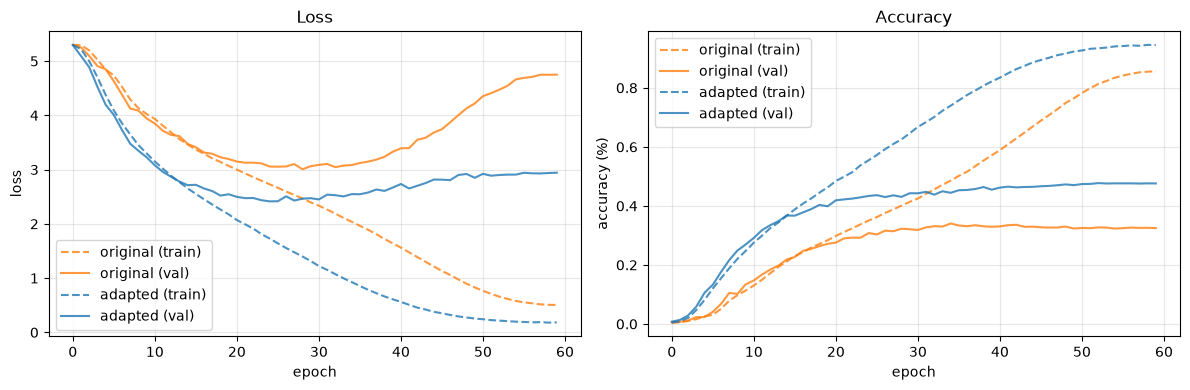

Original best val: 34.04%
Adapted  best val: 47.73%
Gap:               13.69 pp


In [53]:
import pandas as pd
import matplotlib.pyplot as plt

df_orig = pd.read_csv("logs/original/version_0/metrics.csv").groupby("epoch").max()
df_adapt = pd.read_csv("logs/adapted/version_0/metrics.csv").groupby("epoch").max()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

for metric, ax, ylabel in [("Loss", ax1, "loss"), ("Accuracy", ax2, "accuracy (%)")]:
    df_orig.plot(y=[f"{metric}/train", f"{metric}/val"], ax=ax, style=["--C1", "C1"], alpha=0.8, label=["original (train)", "original (val)"])
    df_adapt.plot(y=[f"{metric}/train", f"{metric}/val"], ax=ax, style=["--C0", "C0"], alpha=0.8, label=["adapted (train)", "adapted (val)"])
    ax.set(xlabel="epoch", ylabel=ylabel, title=metric)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# absolute accuracy gap between the two models
print(f"Original best val: {df_orig['Accuracy/val'].max() * 100:.2f}%")
print(f"Adapted  best val: {df_adapt['Accuracy/val'].max() * 100:.2f}%")
print(f"Gap:               {(df_adapt['Accuracy/val'].max() - df_orig['Accuracy/val'].max()) * 100:.2f} pp")